# Section 3 – Unsupervised learning – clustering
In this unsupervised learning task, the objective is to cluster Reddit comments based on the words used
within the comments in them. The aim is to identify patterns and group comments with similar words
together.

In [1]:
%pip install nltk
import nltk
nltk.download('punkt')
nltk.download('wordnet')
%pip install WordCloud

  Using cached nltk-3.9.3-py3-none-any.whl.metadata (3.2 kB)
  Using cached regex-2026.2.19-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (40 kB)
Using cached nltk-3.9.3-py3-none-any.whl (1.5 MB)
Using cached regex-2026.2.19-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl (803 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [nltk]1/2 [nltk]
Note: you may need to restart the kernel to use updated packages.


[nltk_data] Downloading package punkt to
[nltk_data]     /home/students/s346259/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /home/students/s346259/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


  Using cached wordcloud-1.9.6-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (3.4 kB)
Using cached wordcloud-1.9.6-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl (550 kB)
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score, adjusted_mutual_info_score

from wordcloud import WordCloud

In [3]:
data = pd.read_csv(f"without_stopwords_150.csv")
#we actually forgot to remove duplicates/empty rows after removing stopwords, so "we do it now" by creating a mask
mask=[]
for index, row in data.iterrows():
    try:
        if len(row['body'].strip()) == 0:
            mask.append(False)
        else:            
            mask.append(True)
    except:#if NaN
        mask.append(False)
data = data[mask]

#read npy file (pre-processing was done in 'unsupervised-pre-processing.ipynb')
X = np.load('X_reduced_150_lemmatizer_BoW.npy')
X = X[mask]

## KMeans
### Determine the number of clusters

silhouette score computed:  0.4993809376886632
silhouette score computed:  0.2665312357493932
silhouette score computed:  0.2477850830670092
silhouette score computed:  0.2037652697819562
silhouette score computed:  0.20334149332781964
silhouette score computed:  0.22643220863890928
silhouette score computed:  0.18247244626032344


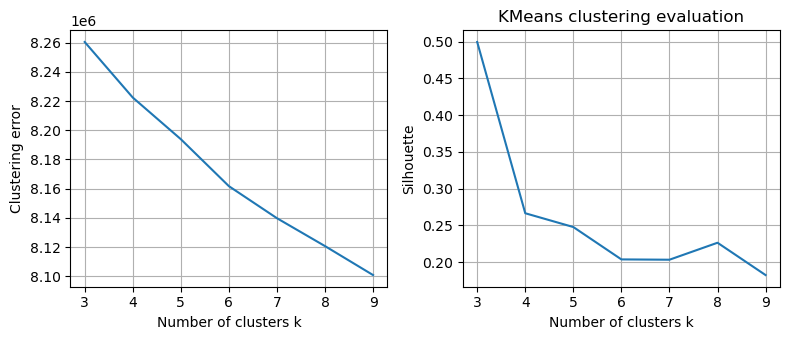

silhouette score computed:  0.5093442139968296
silhouette score computed:  0.2635341134334638
silhouette score computed:  0.2477503377728725
silhouette score computed:  0.1808730404413418
silhouette score computed:  0.2174304953073646
silhouette score computed:  0.2241142115938977
silhouette score computed:  0.1676175120886237


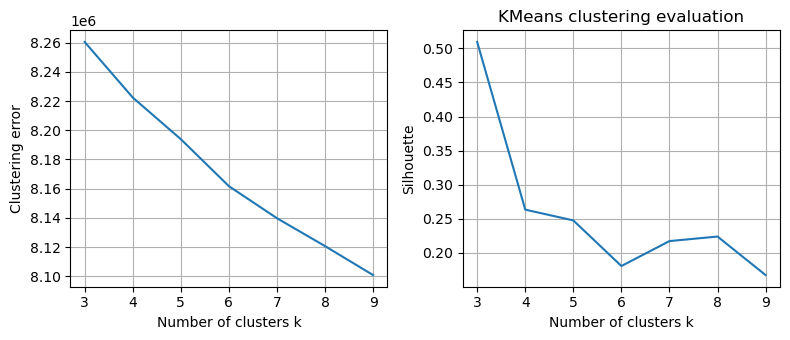

silhouette score computed:  0.462939338607217
silhouette score computed:  0.23959978568478013
silhouette score computed:  0.25200280953328574
silhouette score computed:  0.21074035016264997
silhouette score computed:  0.21355761088218178
silhouette score computed:  0.2301922599118324
silhouette score computed:  0.21682772691873078


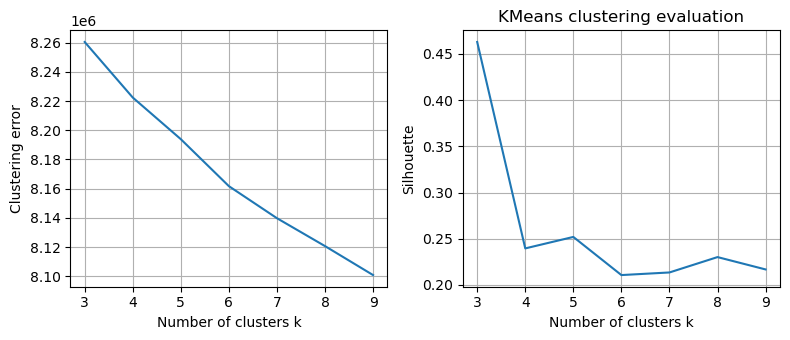

In [4]:
clustering_results = []
k_values=pd.concat([pd.Series(range(3, 10, 1))])

#Performing KMeans for different values of k
for k in k_values:
    kmeans = KMeans(
    init='random', #centroids are initialized randomly
    random_state=42, 
    n_init='auto', #number of times the k-means algorithm will be run with different centroid seeds. 'auto' uses a default value based on init
    max_iter=300,
    tol=1e-2,
    n_clusters=k
    )
    clustering_results.append(kmeans.fit(X))
    #print(f"Fitted KMeans with {k} clusters")#just to have a reference to how much time it's taking to execute

#Computing silhouette scores
n_sample=10000#number of samples to use for silhouette calculation, to speed up the process
for i in range(3):#execute more than once to understand how randomness (of silhouette sampling) affects the results
    silhouetteScores = []
    for result in clustering_results:
        try:
            silhouetteScores.append(silhouette_score(X, result.labels_, sample_size=n_sample))
            print("silhouette score computed: ", silhouetteScores[-1])
        except ValueError as e:
            print(f"Skipping silhouette calculation due to error: {e}")
            silhouetteScores.append(-1)

    # Plotting the results
    fig, axs = plt.subplots(1,2, figsize=(8, 3.5))
    plt.title("KMeans clustering evaluation")

    axs[0].plot(
        [k for k in k_values], 
        [result.inertia_ for result in clustering_results]
    )
    axs[0].set_xlabel("Number of clusters k")
    axs[0].set_ylabel("Clustering error")
    axs[0].grid()
    
    axs[1].plot(
        [k for k in k_values], 
        [s for s in silhouetteScores]
    )
    axs[1].set_xlabel("Number of clusters k")
    axs[1].set_ylabel("Silhouette")
    axs[1].grid()
    plt.tight_layout()
    plt.show()

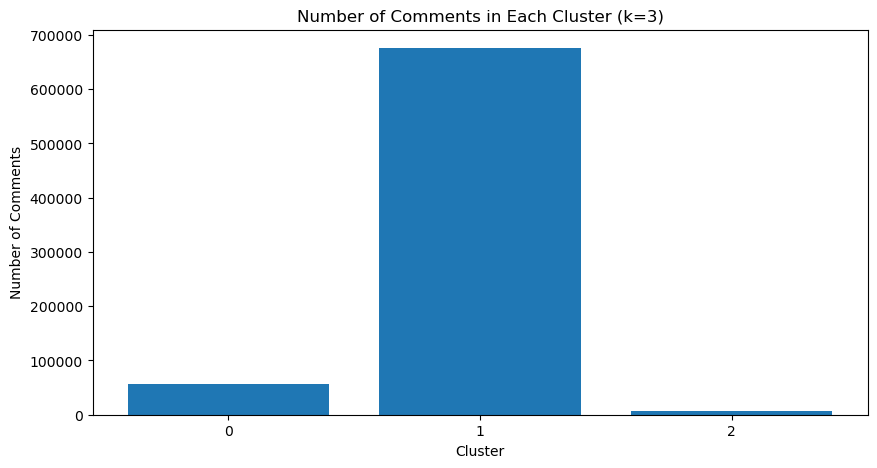

Cluster sizes:
 1    675677
0     57430
2      6237
Name: count, dtype: int64


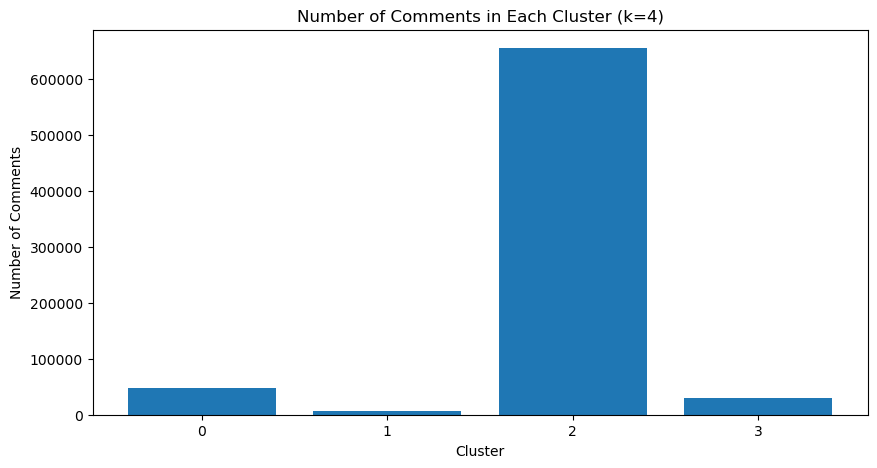

Cluster sizes:
 2    655194
0     48190
3     29910
1      6050
Name: count, dtype: int64


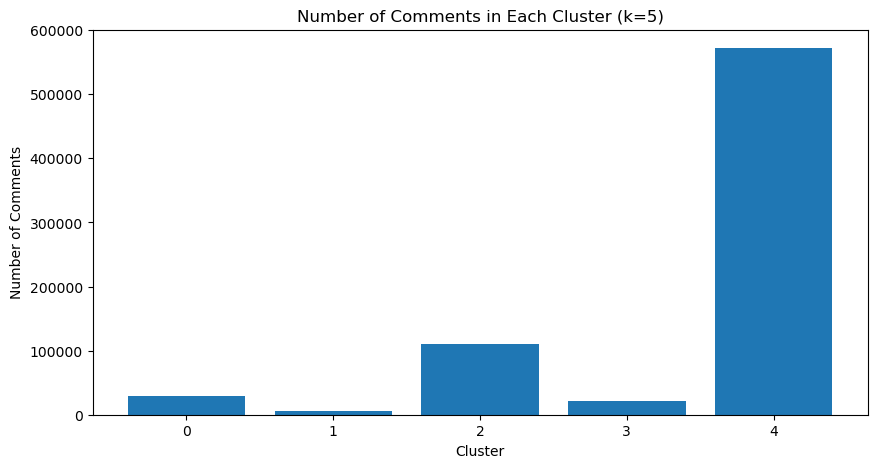

Cluster sizes:
 4    572137
2    110842
0     29718
3     20772
1      5875
Name: count, dtype: int64


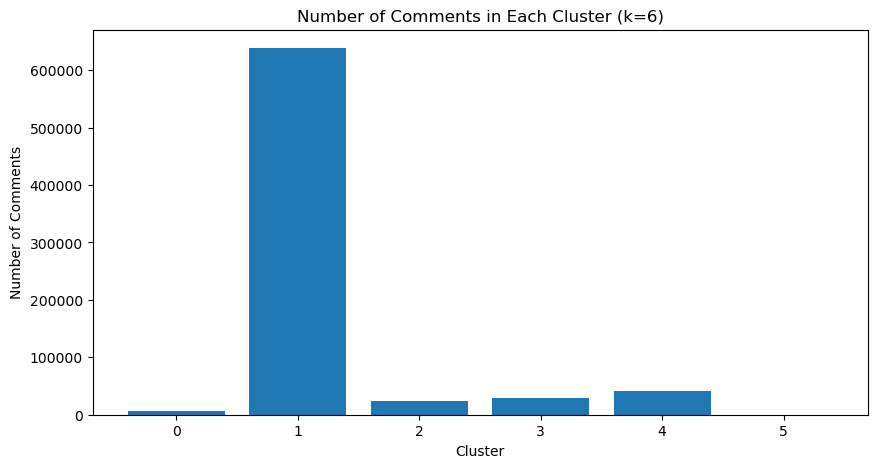

Cluster sizes:
 1    638579
4     41717
3     29066
2     24111
0      5643
5       228
Name: count, dtype: int64


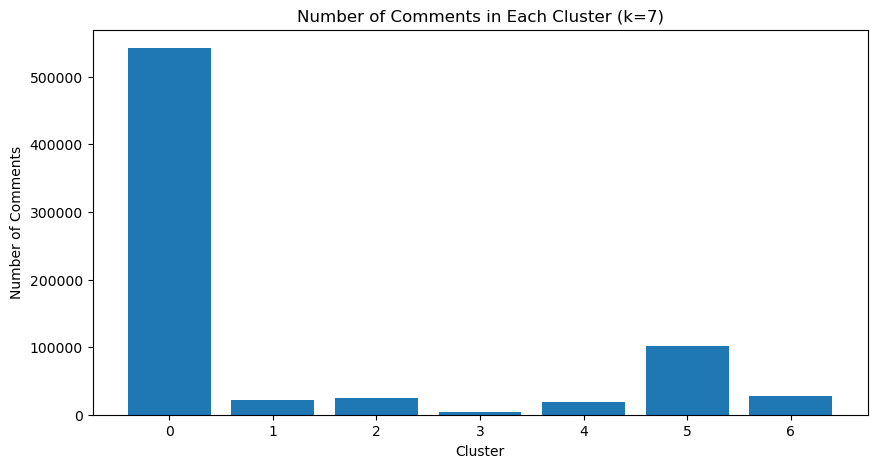

Cluster sizes:
 0    542471
5    100969
6     27902
2     24011
1     21173
4     18767
3      4051
Name: count, dtype: int64


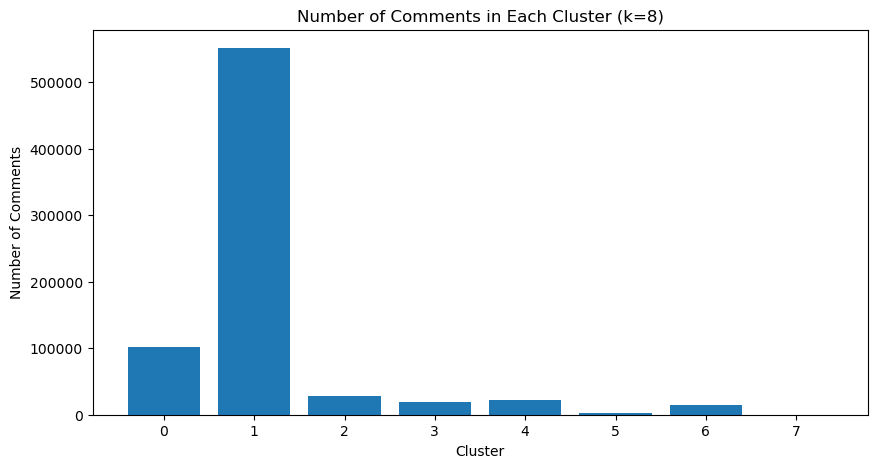

Cluster sizes:
 1    551224
0    102357
2     28348
4     21548
3     19303
6     14350
5      1986
7       228
Name: count, dtype: int64


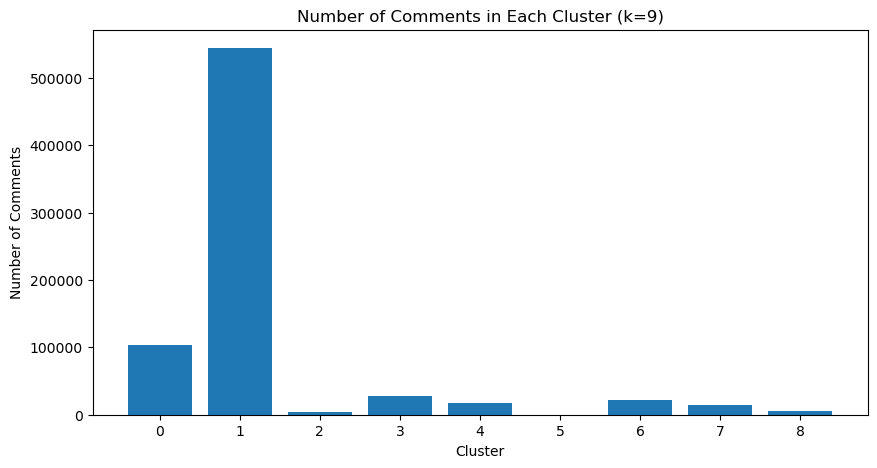

Cluster sizes:
 1    544212
0    103860
3     27488
6     21269
4     17789
7     14228
8      5670
2      4600
5       228
Name: count, dtype: int64


In [5]:
#Plot the number of comments for each cluster
for i in clustering_results:
    cluster_sizes = pd.Series(i.labels_).value_counts()
    plt.figure(figsize=(10, 5))
    plt.bar(cluster_sizes.index, cluster_sizes.values)
    plt.title(f"Number of Comments in Each Cluster (k={len(cluster_sizes)})")
    plt.xlabel("Cluster")
    plt.ylabel("Number of Comments")
    plt.xticks(cluster_sizes.index)
    plt.show()
    print("Cluster sizes:\n", cluster_sizes)

In [6]:
numberOfChoosenClusters=3
indexOfChoosenCluster=k_values[k_values==numberOfChoosenClusters].index[0]

### User Distribution Analysis
Analyze how the users are distributed (each user can be assigned to more clusters because we
are clustering comments). 
#### Show the ECDF of number of clusters assigned to each user.

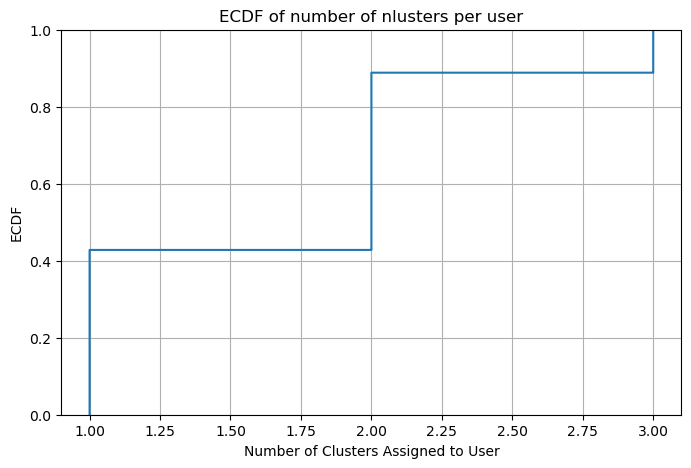

In [7]:
data["cluster"]= clustering_results[indexOfChoosenCluster].labels_
user_clusters = data.groupby('author')['cluster'].nunique().reset_index()#grouping by author
#user clusters is now a series with author and number of clusters
user_clusters.columns = ['author', 'num_clusters']#turn it into a DF

# Filter user_clusters to only those authors who have multiple comments
authors_with_multiple_comments = data.groupby('author')['body'].nunique()
authors_with_multiple_comments = authors_with_multiple_comments[authors_with_multiple_comments > 1].index
user_clusters = user_clusters[user_clusters['author'].isin(authors_with_multiple_comments)]

plt.figure(figsize=(8, 5))
sns.ecdfplot(data=user_clusters, x='num_clusters')
plt.xlabel('Number of Clusters Assigned to User')
plt.ylabel('ECDF')
plt.title('ECDF of number of nlusters per user')
plt.grid(True)
plt.show()

#### Use the first two components of the ~~PCA~~ TruncatedSVD. Then visualize on these two dimensions to gain insights into their distribution and separability

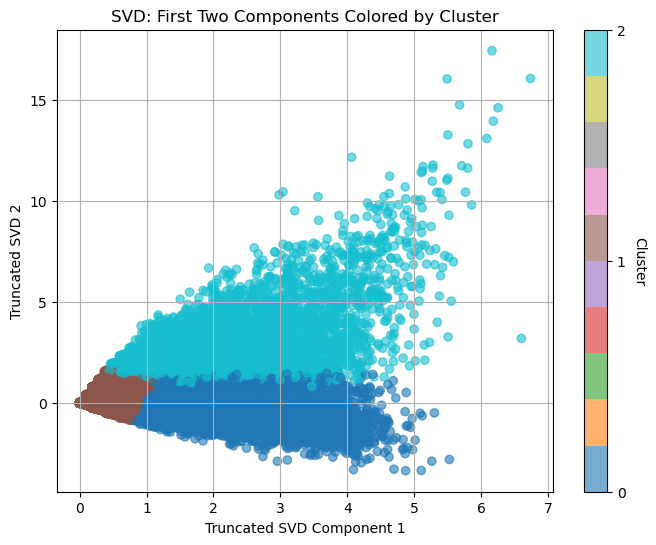

In [8]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X[:, 0], X[:, 1], c=data['cluster'], cmap='tab10', alpha=0.6)
plt.xlabel('Truncated SVD Component 1')
plt.ylabel('Truncated SVD 2')
plt.title('SVD: First Two Components Colored by Cluster')
cbar = plt.colorbar(scatter, label='Cluster', ticks=np.unique(data['cluster']))
cbar.set_label('Cluster', rotation=270, labelpad=15)
plt.grid(True)
plt.show()

### Cluster analysis
Analyze the characteristics of each cluster. This might involve examining the most frequent
words in each cluster (try word cloud). HINT: the most used words are not always the most
representative, for example word ‘the’ will be very popular in every cluster if you didn’t remove it from the dataset. Try to understand which are the most representative

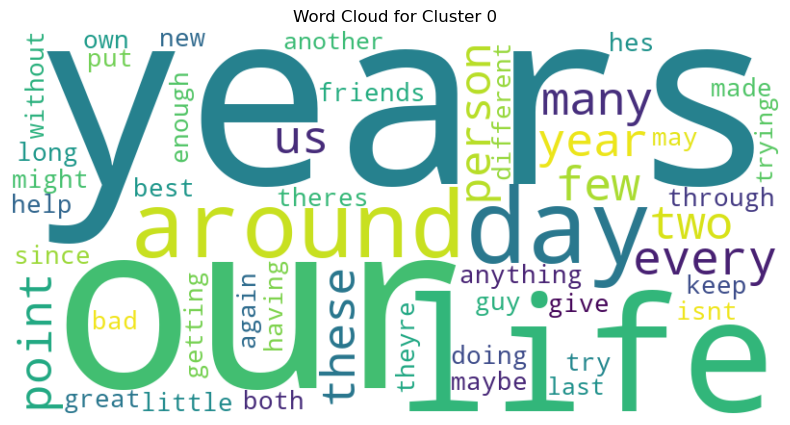

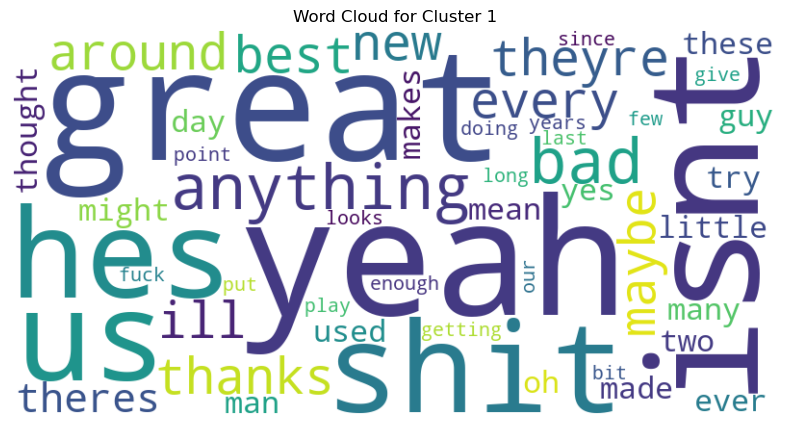

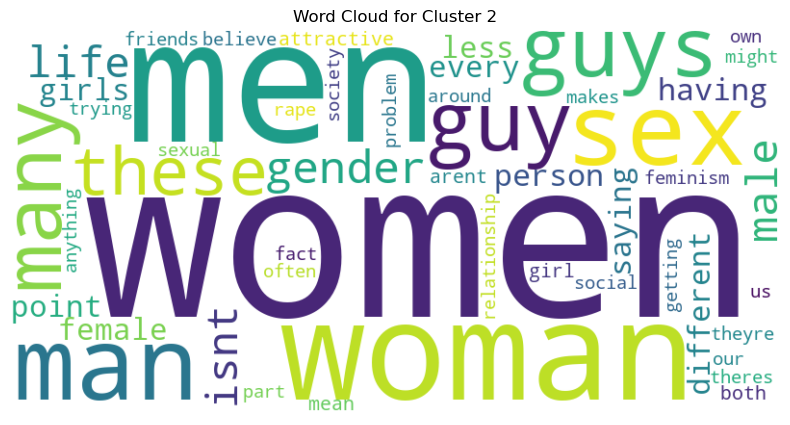

In [9]:
#Group by cluster and concatenate all comments in each cluster, then compute TF-IDF to understand important words in each cluster
cluster_documents=data[['body','cluster']].groupby('cluster').agg(' '.join).reset_index()
tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(cluster_documents['body'])
terms = tfidf_vectorizer.get_feature_names_out()

#For each cluster, get the top 50 words by TF-IDF score and plot a word cloud
for cluster_num in range(numberOfChoosenClusters):
    tfidf_scores = tfidf_matrix[cluster_num].toarray().flatten()
    top_indices = np.argsort(tfidf_scores)[-50:]  # Get indices of top 50 words
    top_terms = {terms[i]: tfidf_scores[i] for i in top_indices}

    wordcloud = WordCloud(width=800, height=400, background_color='white').generate_from_frequencies(top_terms)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(f'Word Cloud for Cluster {cluster_num}')
    plt.show()

Finally, analyze and visualize how the subreddit are distributed among the found clusters. Are there pure clusters where only few related
subreddits end up?

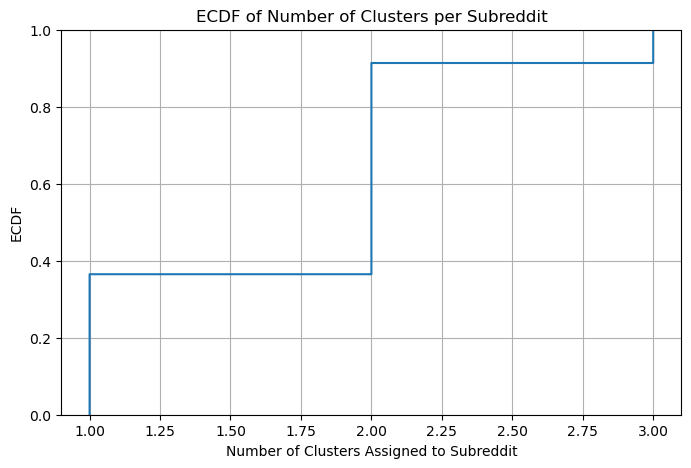

In [10]:
subreddit_cluster = data.groupby('subreddit')['cluster'].nunique().reset_index()#grouping by subreddit
#subreddit clusters is now a series with subreddit and number of clusters
subreddit_cluster.columns = ['subreddit', 'num_clusters']#turn it into a DF

# Filter subreddit_cluster to only those subreddits that have multiple comments
subreddits_with_multiple_comments = data.groupby('subreddit')['body'].nunique()
subreddits_with_multiple_comments = subreddits_with_multiple_comments[subreddits_with_multiple_comments > 1].index
subreddit_cluster = subreddit_cluster[subreddit_cluster['subreddit'].isin(subreddits_with_multiple_comments)]

plt.figure(figsize=(8, 5))
sns.ecdfplot(data=subreddit_cluster, x='num_clusters')
plt.title('ECDF of Number of Clusters per Subreddit')
plt.xlabel('Number of Clusters Assigned to Subreddit')
plt.ylabel('ECDF')
plt.grid(True)
plt.show()

Cluster 0 has 57430 comments


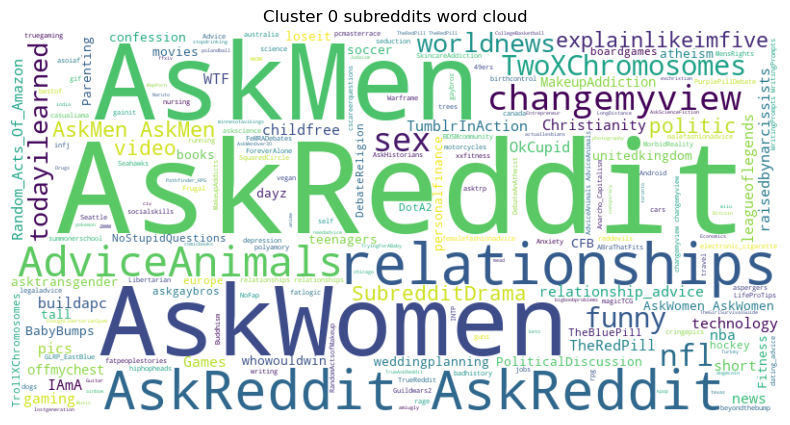

Cluster 1 has 675677 comments


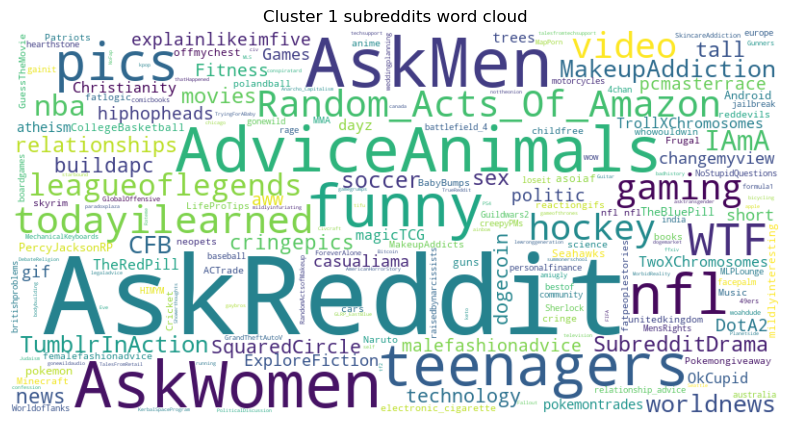

Cluster 2 has 6237 comments


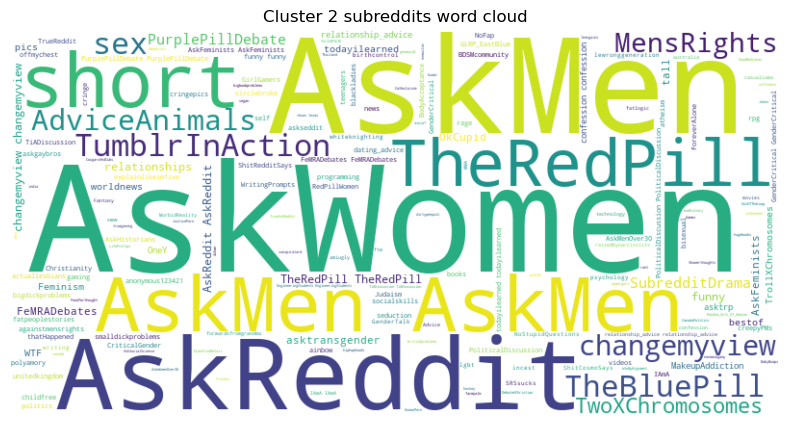

In [11]:
subredditsNames = []
for i in range(0, numberOfChoosenClusters):
    cluster_sizes = data['cluster'].value_counts()
    print(f"Cluster {i} has {cluster_sizes[i]} comments")
    subredditsNames.append(" ".join(data[data['cluster'] == i]['subreddit'].values))
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(subredditsNames[i])

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')  
    plt.title(f"Cluster {i} subreddits word cloud")
    plt.show()

#### Do clusters reflect subreddit division?

In [12]:
ari = adjusted_rand_score(data["subreddit"], data["cluster"])
nmi = normalized_mutual_info_score(data["subreddit"], data["cluster"])
ami = adjusted_mutual_info_score(data["subreddit"], data["cluster"])

print("ARI:", ari)
print("NMI:", nmi)
print("AMI:", ami)

ARI: 0.0003397059979674387
NMI: 0.012133874018883335
AMI: 0.01063116657666238


Another thing we can try is to analyze how long are comments in the different clusters, the idea is that the shorter comments are closer to "0" than the longer cluster, considering the trend in length of comments the biggest cluster may contain those shorter comments

Text(0.5, 0, 'Cluster')

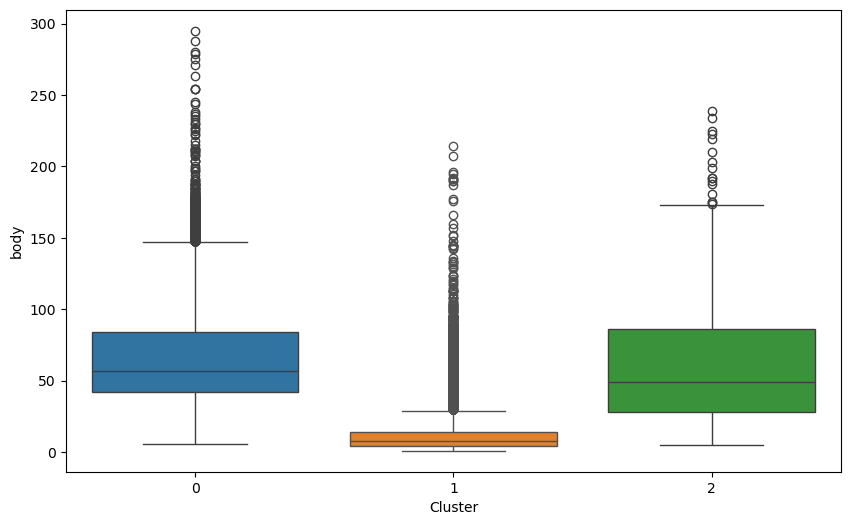

In [13]:
#plot for each cluster the length of comments (boxplot)
plt.figure(figsize=(10, 6))
for i in range(numberOfChoosenClusters):
    cluster_data = data[data['cluster'] == i]
    sns.boxplot(x=cluster_data['cluster'], y=cluster_data['body'].apply(lambda x: len(x.split())))
plt.xlabel('Cluster')

In [15]:
#store cluster labels in case we want to analyze further later
np.save('kmeans_cluster_labels.npy', data['cluster'].values)

## HDBSCAN
### Clustering

In [ ]:
%reset -f 
#reset kernel
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import HDBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score, adjusted_mutual_info_score
from sklearn.model_selection import train_test_split

from wordcloud import WordCloud

We could not execute HDBSCAN on the whole dataset due to memory constraint, therefore we used a subsample.
We considered using KMeans results

In [3]:
subsample_mask = np.load("subsample_mask.npy")
data = pd.read_csv(f"without_stopwords_150.csv")
#we actually forgot to remove duplicates/empty rows after removing stopwords, so "we do it now" by creating a mask
mask=[]
for index, row in data.iterrows():
    try:
        if len(row['body'].strip()) == 0:
            mask.append(False)
        else:            
            mask.append(True)
    except:#if NaN
        mask.append(False)

data = data[mask]
data=data[subsample_mask]

#read npy file (pre-processing was done in 'unsupervised-pre-processing.ipynb')
X = np.load('X_reduced_150_lemmatizer_BoW.npy')
X = X[mask]
X=X[subsample_mask]

In [4]:
# From the tests we did on the subsample, we know that HDBSCAN takes around 30 minutes to execute on 20,000 comments
# so executing this would take too much time

# hdbscan_results = []

# min_cluster_sizes = [3, 5, 10]
# cluster_selection_epsilons = [0.0, 0.1, 0.2]

# score_No_Outliers = []
# score=[]
# number_of_outliers=[]

# for cluster_size in min_cluster_sizes:
#     scores_temp=[]
#     number_of_outliers_temp=[]
#     score_No_Outliers_temp=[]
#     for epsilon in cluster_selection_epsilons:
#         hdbscan = HDBSCAN(
#             min_cluster_size=cluster_size,
#             cluster_selection_epsilon=epsilon,
#             metric='cosine',
#             cluster_selection_method='leaf',
#             )
#         hdbscan_results=hdbscan.fit(X)

#         # compute silhouette score only of clustered samples (not noise, i.e., not -1)
#         mask = hdbscan_results.labels_ != -1

#         score_No_Outliers_temp.append(silhouette_score(X[mask], hdbscan_results.labels_[mask]))
#         number_of_outliers_temp.append(np.sum(hdbscan_results.labels_ == -1))
#         scores_temp.append(silhouette_score(X, hdbscan_results.labels_))
#         # print("HDBSCAN parameters:", params)
#         # print("Silhouette score:", score)
#         # print("Silhouette score (clustered samples only):", score_No_Outliers)
#         # print("Number of outliers detected:", np.sum(hdbscan_results.labels_ == -1))
#         # print("\n")

#     score_No_Outliers.append(score_No_Outliers_temp)
#     score.append(scores_temp)
#     number_of_outliers.append(number_of_outliers_temp)

# #plot the results
# score_df = pd.DataFrame(score, index=min_cluster_sizes, columns=cluster_selection_epsilons)
# score_No_Outliers_df = pd.DataFrame(score_No_Outliers, index=min_cluster_sizes, columns=cluster_selection_epsilons)
# number_of_outliers_df = pd.DataFrame(number_of_outliers, index=min_cluster_sizes, columns=cluster_selection_epsilons)

# sns.heatmap(score_df, annot=True, cmap="coolwarm", cbar=True)
# plt.title("Silhouette Score Heatmap")
# plt.show()

# sns.heatmap(score_No_Outliers_df, annot=True, cmap="coolwarm", cbar=True)
# plt.title("Silhouette Score (No Outliers) Heatmap")
# plt.show()

# sns.heatmap(number_of_outliers_df, annot=True, cmap="coolwarm", cbar=True)
# plt.title("Number of Outliers Heatmap")
# plt.show()

In [5]:
#train with the best params
hdbscan = HDBSCAN(
    min_cluster_size=6,
    min_samples=3,#When not set (default value = 6) we got 14911 outliers (too many so lower the value),
    cluster_selection_method="leaf",#Should produce more clusters than default
)
hdbscan_results=hdbscan.fit(X)
#hdbscan.condensed_tree_.plot()

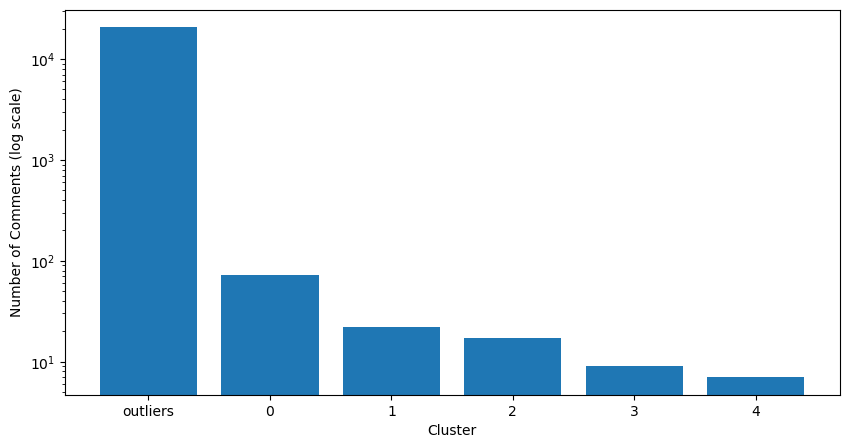

Cluster sizes: cluster
-1    20685
 0       72
 3       22
 4       17
 1        9
 2        7
Name: count, dtype: int64


In [ ]:
data["cluster"]= hdbscan_results.labels_
plt.figure(figsize=(10, 5))
cluster_sizes = data["cluster"].value_counts()

plt.bar(["outliers"]+[str(i) for i in range(0,cluster_sizes.shape[0]-1)], cluster_sizes.values)
#plt.title(f"Number of Comments in Each Cluster (k={numberOfChoosenClusters})")
plt.xlabel("Cluster")
plt.ylabel("Number of Comments (log scale)")
#plt.xticks(cluster_sizes.index.insert(0, "outliers"))
#log scale on y axis
plt.yscale('log')
plt.show()
print("Cluster sizes:", cluster_sizes)

data_no_outliers = data[data["cluster"]!=-1]#remove outliers
cluster_sizes = data_no_outliers["cluster"].value_counts()


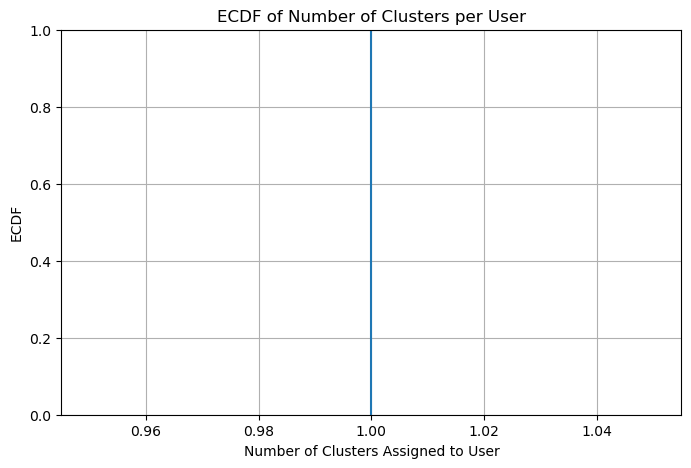

In [7]:
user_clusters = data_no_outliers.groupby('author')['cluster'].nunique().reset_index()#grouping by author
#user clusters is now a series with author and number of clusters
user_clusters.columns = ['author', 'num_clusters']#turn it into a DF

# Filter user_clusters to only those authors who have multiple comments
authors_with_multiple_comments = data_no_outliers.groupby('author')['body'].nunique()
authors_with_multiple_comments = authors_with_multiple_comments[authors_with_multiple_comments > 1].index
user_clusters = user_clusters[user_clusters['author'].isin(authors_with_multiple_comments)]

plt.figure(figsize=(8, 5))
sns.ecdfplot(data=user_clusters, x='num_clusters')
plt.xlabel('Number of Clusters Assigned to User')
plt.ylabel('ECDF')
plt.title('ECDF of Number of Clusters per User')
plt.grid(True)
plt.show()

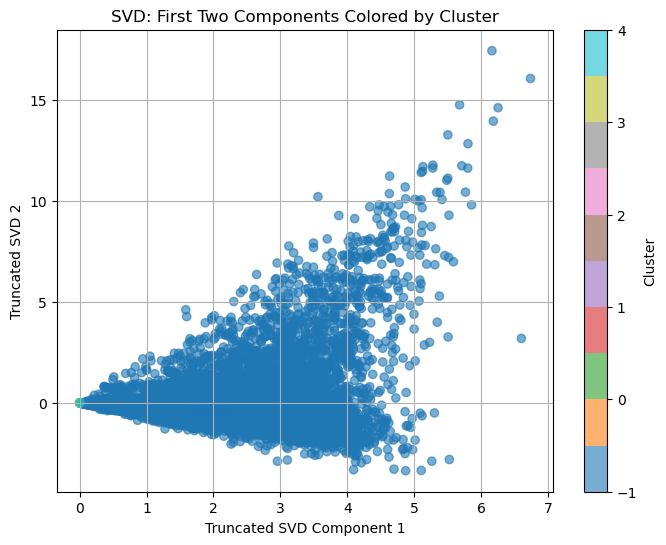

In [8]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X[:, 0], X[:, 1], c=data['cluster'], cmap='tab10', alpha=0.6)
plt.xlabel('Truncated SVD Component 1')
plt.ylabel('Truncated SVD 2')
plt.title('SVD: First Two Components Colored by Cluster')
plt.colorbar(scatter, label='Cluster')
plt.grid(True)
plt.show()

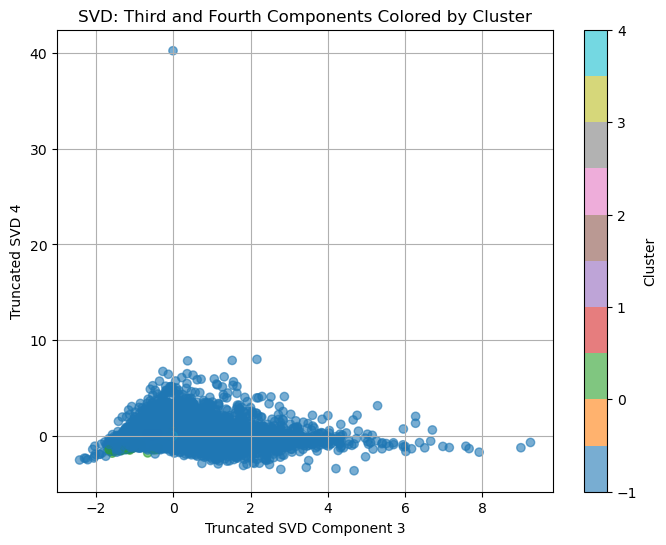

In [9]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X[:, 2], X[:, 3], c=data['cluster'], cmap='tab10', alpha=0.6)
plt.xlabel('Truncated SVD Component 3')
plt.ylabel('Truncated SVD 4')
plt.title('SVD: Third and Fourth Components Colored by Cluster')
plt.colorbar(scatter, label='Cluster')
plt.grid(True)
plt.show()

cluster 0 has 72 comments


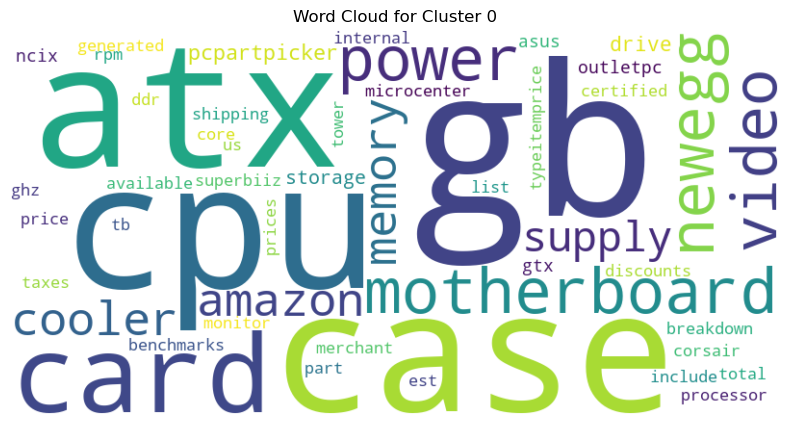

cluster 3 has 22 comments


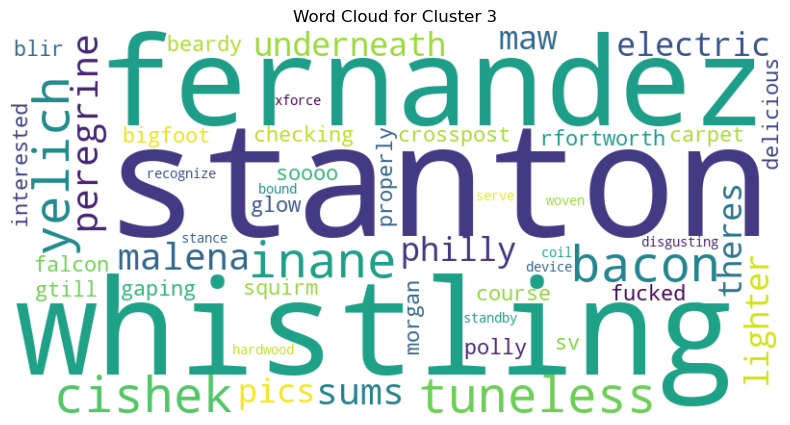

cluster 4 has 17 comments


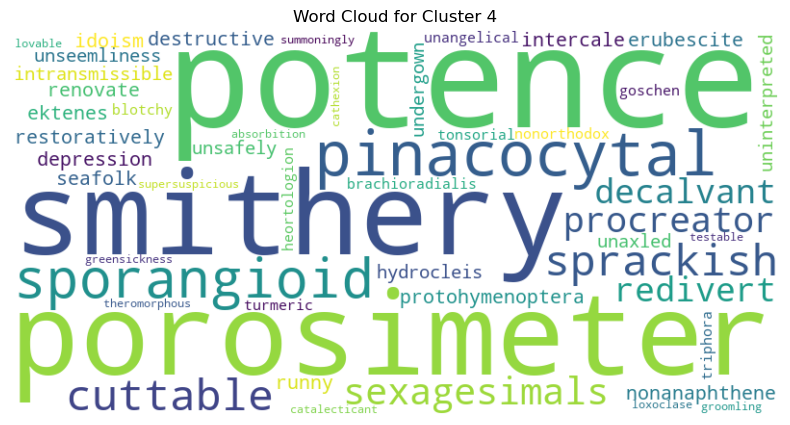

cluster 2 has 7 comments


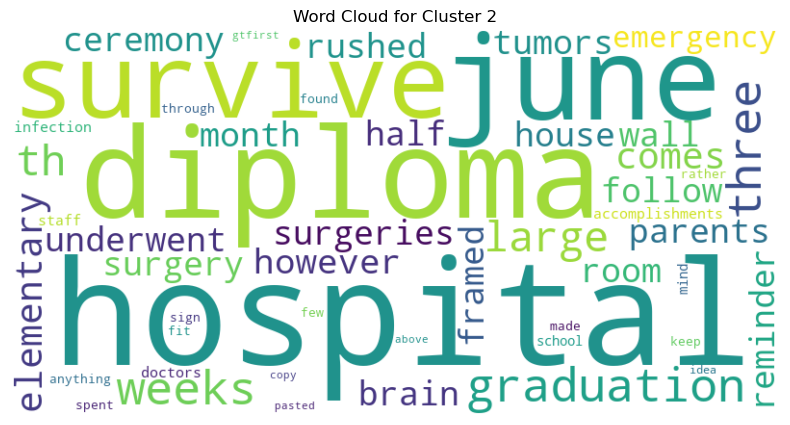

tough          happen   life    comes  mind    elementary school diploma  few weeks  graduation   rushed   hospital   doctors  found three large brain tumors  underwent emergency surgery  spent  three   half weeks   hospital  follow  surgeries   staff infection      hospital  june th  made    graduation ceremony  june th    diploma    wall   room   parents house   keep    sign   accomplishments   reminder     survive      through  month   survive anything however  rather large    framed         fit
        long life ahead    honestly   idea yet  put  idea      far  another comment above however gtfirst   comes  mind    elementary school diploma  few weeks  graduation   rushed   hospital   doctors  found three large brain tumors  underwent emergency surgery  spent  three   half weeks   hospital  follow  surgeries   staff infection      hospital  june th  made    graduation ceremony  june th    diploma    wall   room   parents house   keep    sign   accomplishments   reminder     survive

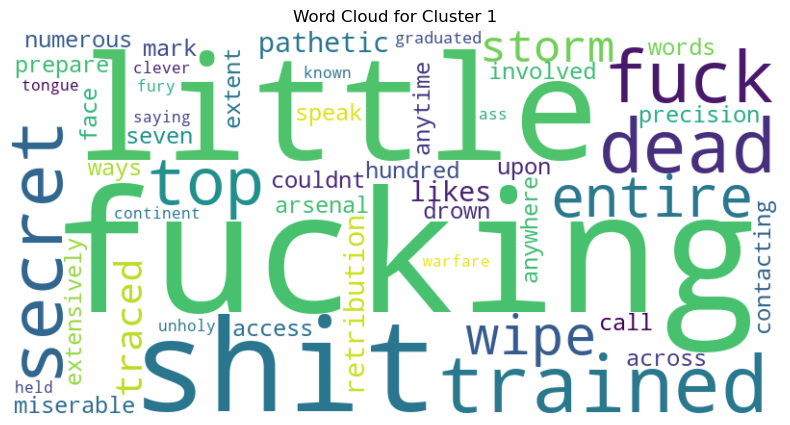

  fuck    fucking     little bitch ill     graduated top   class   navy seals    involved  numerous secret raids  alquaeda     confirmed kills   trained  gorilla warfare    top sniper   entire us armed forces   nothing     another target   wipe   fuck   precision  likes      seen    earth mark  fucking words      away  saying  shit     internet  again fucker   speak   contacting  secret network  spies across  usa   ip   traced      prepare   storm maggot  storm  wipes   pathetic little   call  life  fucking dead kid    anywhere anytime    kill    seven hundred ways      bare hands     extensively trained  unarmed combat    access   entire arsenal   united states marine corps        full extent  wipe  miserable ass   face   continent  little shit      known  unholy retribution  little clever comment    bring  upon  maybe    held  fucking tongue   couldnt      paying  price  goddamn idiot   shit fury       drown    fucking dead kiddo uprons   left
  fuck    fucking     little bitch ill  

In [10]:
#Group by cluster and concatenate all comments in each cluster, then compute TF-IDF to understand important words in each cluster
cluster_documents=data_no_outliers[['body','cluster']].groupby('cluster').agg(' '.join).reset_index()
tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(cluster_documents['body'])
terms = tfidf_vectorizer.get_feature_names_out()

#List the first 3 largest clusters
clusters_to_plot = data_no_outliers['cluster'].value_counts().nlargest(3).index
#add two clusters from the smallest
clusters_to_plot = clusters_to_plot.append(data_no_outliers['cluster'].value_counts().nsmallest(2).index)

#For each cluster, get the top 50 words by TF-IDF score and plot a word cloud
for cluster_num in clusters_to_plot:
    tfidf_scores = tfidf_matrix[cluster_num].toarray().flatten()
    top_indices = np.argsort(tfidf_scores)[-50:]  # Get indices of top 50 words
    top_terms = {terms[i]: tfidf_scores[i] for i in top_indices}

    wordcloud = WordCloud(width=800, height=400, background_color='white').generate_from_frequencies(top_terms)

    print(f"cluster {cluster_num} has {cluster_sizes[cluster_num]} comments")
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(f'Word Cloud for Cluster {cluster_num}')
    plt.show()
    if cluster_sizes[cluster_num]<10:
        for comment in data_no_outliers[data_no_outliers['cluster'] == cluster_num]['body'].values:
            print(comment)


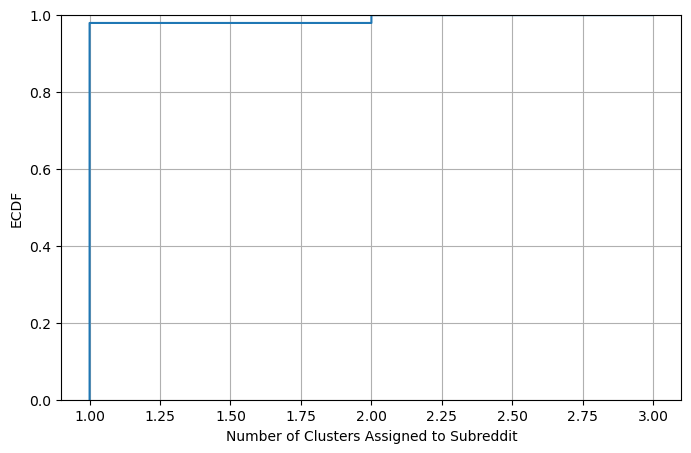

In [11]:
subreddit_cluster = data.groupby('subreddit')['cluster'].nunique().reset_index()#grouping by subreddit
#subreddit clusters is now a series with subreddit and number of clusters
subreddit_cluster.columns = ['subreddit', 'num_clusters']#turn it into a DF

# Filter subreddit_cluster to only those subreddits that have multiple comments
subreddits_with_multiple_comments = data.groupby('subreddit')['body'].nunique()
subreddits_with_multiple_comments = subreddits_with_multiple_comments[subreddits_with_multiple_comments > 1].index
subreddit_cluster = subreddit_cluster[subreddit_cluster['subreddit'].isin(subreddits_with_multiple_comments)]

plt.figure(figsize=(8, 5))
sns.ecdfplot(data=subreddit_cluster, x='num_clusters')
plt.xlabel('Number of Clusters Assigned to Subreddit')
plt.ylabel('ECDF')
plt.grid(True)
plt.show()

Cluster 0 has 72 comments and 5 subreddits


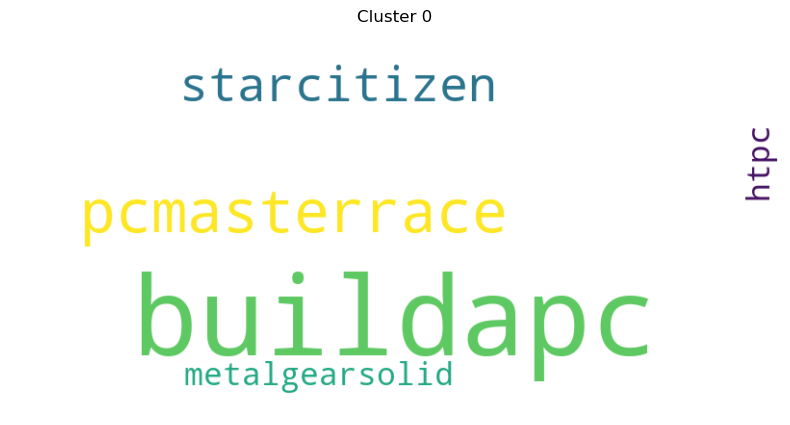

Cluster 3 has 22 comments and 22 subreddits


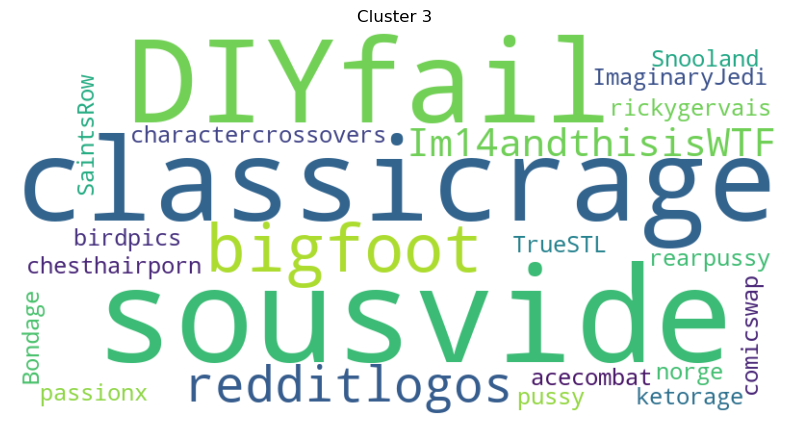

Cluster 4 has 17 comments and 10 subreddits


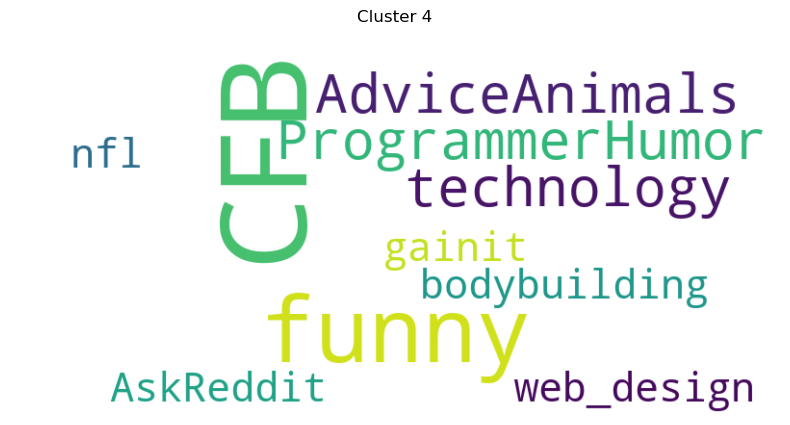

Cluster 2 has 7 comments and 1 subreddits


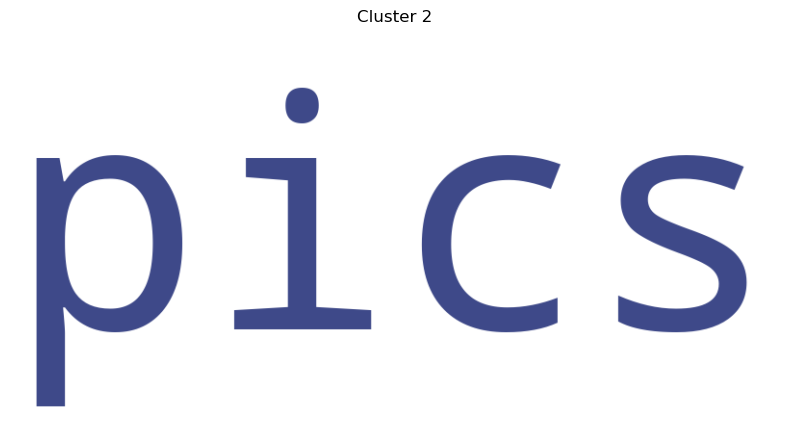

Cluster 1 has 9 comments and 9 subreddits


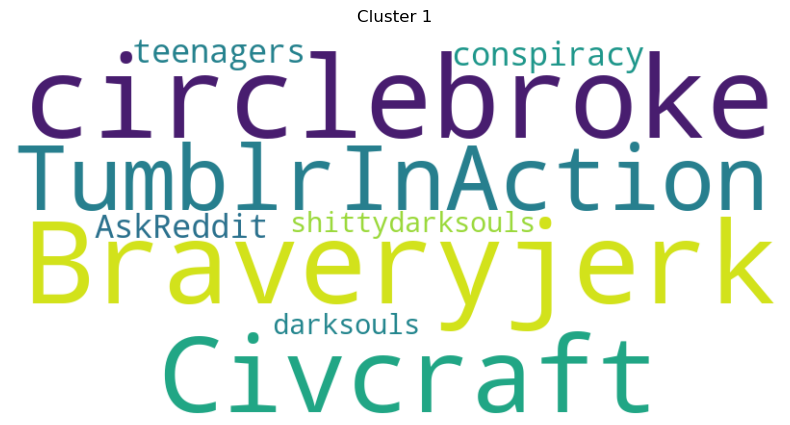

In [12]:
#List the first 3 largest clusters
clusters_to_plot = data_no_outliers['cluster'].value_counts().nlargest(3).index
#add two clusters from the smallest
clusters_to_plot = clusters_to_plot.append(data_no_outliers['cluster'].value_counts().nsmallest(2).index)

#For each cluster, get the top 50 words by TF-IDF score and plot a word cloud
for cluster_num in clusters_to_plot:
    cluster_sizes = data_no_outliers['cluster'].value_counts()
    subredditsNames = " ".join(data_no_outliers[data_no_outliers['cluster'] == cluster_num]['subreddit'].values)
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(subredditsNames)

    print(f"Cluster {cluster_num} has {cluster_sizes[cluster_num]} comments and {data_no_outliers[data_no_outliers['cluster'] == cluster_num]['subreddit'].nunique()} subreddits")
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')  
    plt.title(f"Cluster {cluster_num}")
    plt.show()

In [ ]:
ari = adjusted_rand_score(data["subreddit"], data["cluster"])
nmi = normalized_mutual_info_score(data["subreddit"], data["cluster"])
ami = adjusted_mutual_info_score(data["subreddit"], data["cluster"])

print("ARI:", ari)
print("NMI:", nmi)
print("AMI:", ami)

ARI: 0.00031799402265146224
NMI: 0.010780969148764693
AMI: 0.004873803340677339
